## Project: Segmentation of Cloudy Regions
### Step 1 : Data Exploration & Understanding

✅ Dataset structure
→ Understanding train.csv, columns, rows, and dataset format

✅ Image and cloud extraction
→ Separating Image_Label into Image and Cloud_Type

✅ Missing values analysis
→ Understanding NaN values in EncodedPixels as absence of cloud category

✅ Segmentation Mask & RLE understanding
→ Understanding how cloud regions are represented and stored using Run-Length Encoding (RLE)

✅ Cloud distribution
→ Checking annotation-level distribution of cloud categories

✅ Visualization of Cloud Type Presence
→ Checking real cloud occurrences using available masks only

✅ Number of unique images
→ Determining the real number of satellite images in the dataset

✅ Mask availability per image
→ Verifying whether every image contains at least one cloud mask

✅ Number of masks per image distribution
→ Exploring how many cloud masks are present in each satellite image

✅ RLE Feature Extraction and Mask Characteristics
→ Converting RLE strings into numerical features describing cloud masks (`num_runs`, `total_pixels`, `mean_length`, `max_length`, `min_length`)

✅ Distribution of Cloud Area
→ Analyzing the distribution of cloud mask sizes using `total_pixels`

✅ Outlier Detection
→ Identifying unusually large cloud masks using Boxplot and the IQR method

✅ Cloud Area Comparison Between Cloud Types
→ Comparing cloud size (`total_pixels`) across different cloud categories

✅ Cloud Mask Complexity Comparison
→ Comparing mask complexity (`num_runs`) across cloud categories

✅ Correlation Analysis of RLE Features
→ Investigating relationships between extracted mask features using a correlation heatmap

✅ Visual Validation of Cloud Masks
→ Reconstructing binary cloud masks from RLE encoding and validating the decoding process

✅ RLE Decoding Verification
→ Checking whether the decoded masks preserve the correct dimensions and cloud pixel counts

✅ Visualizing the Decoded Cloud Mask
→ Displaying reconstructed cloud masks to understand the spatial structure of cloud regions

✅ Overlay Mask on Original Satellite Image
→ Overlaying the decoded cloud mask on the original satellite image to verify whether reconstructed cloud regions correspond to actual cloud structures

#### Step 1.1 : Dataset structure 

In this step, we explore the dataset structure and understand the training data before modeling.

The dataset contains four main files:

- `train.csv`: Contains image annotations, cloud categories, and segmentation masks encoded using Run-Length Encoding (RLE). This is the main dataset used for exploration.
- `train_images/`: Contains the corresponding satellite images used for visualization.
- `test_images/`: Contains unlabeled images that will be used later for prediction.
- `sample_submission.csv`: Provides the required format for the final submission.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/home/ubuntu/Cloud_Project/train.csv")

In [3]:
display(df.shape)
print("-------"*20)

display(df.head())
print("-------"*20)

display(df.info())
print("-------"*20)

(22184, 2)

--------------------------------------------------------------------------------------------------------------------------------------------


,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...


--------------------------------------------------------------------------------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 22184 entries, 0 to 22183
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Image_Label    22184 non-null  str  
 1   EncodedPixels  11836 non-null  str  
dtypes: str(2)
memory usage: 346.8 KB


None

--------------------------------------------------------------------------------------------------------------------------------------------


### Dataset Size and Structure

The training dataset contains **22,184 annotation records** and **2 columns**:

- `Image_Label`: Contains the image name and the corresponding cloud type.
- `EncodedPixels`: Contains the segmentation mask information.

The dataset contains **11,836 available segmentation masks**, while the remaining records have missing values in the `EncodedPixels` column. These missing values indicate that the corresponding cloud type is not present in the image.

### 📎 Segmentation Mask

A segmentation mask is a pixel-level representation that shows which parts of an image belong to a specific object or region.

In this project, the mask identifies the pixels corresponding to cloud regions in satellite images. Pixels belonging to clouds are labeled as part of the mask, while the remaining pixels represent non-cloud areas.

### 📎 Segmentation Mask Representation (RLE)

The segmentation masks are stored using **Run-Length Encoding (RLE)**.

Instead of storing each pixel value individually, RLE represents cloud regions by storing the starting positions and lengths of consecutive pixels belonging to the mask.

This representation provides a compact way to store segmentation masks and will be further analyzed to extract mask-related features.

The Run-Length Encoding (RLE) format stores information as pairs:

* Start position: the pixel position where a cloud region starts
* Length: the number of consecutive pixels belonging to the cloud region

```python

starts = numbers[0::2]

lengths = numbers[1::2]

```
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.2 : Image and cloud extraction

The `Image_Label` column contains two pieces of information: the image name and the corresponding cloud category.

For example:

0011165.jpg_Fish

To make the dataset easier to analyze, this column was separated into two new columns:

- `Image`: Contains the satellite image name.
- `Cloud_Type`: Contains the cloud category.

This separation allows us to work with image information and cloud labels independently in the following analysis steps.

In [4]:
df["Image"] = df["Image_Label"].str.split("_").str[0]

df["Cloud_Type"] = df["Image_Label"].str.split("_").str[1]

display(df.head())

print("-------"*20)

,Image_Label,EncodedPixels,Image,Cloud_Type
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,Fish
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,Flower
2,0011165.jpg_Gravel,NaN,0011165.jpg,Gravel
3,0011165.jpg_Sugar,NaN,0011165.jpg,Sugar
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,Fish


--------------------------------------------------------------------------------------------------------------------------------------------


### Step 1.3 : Missing Values Analysis

After separating the image and cloud type information, missing values were analyzed to better understand the availability of segmentation annotations.

The analysis shows that:

- `Image_Label`, `Image`, and `Cloud_Type` do not contain missing values.
- `EncodedPixels` contains missing values.

Since each image has four records corresponding to the four cloud categories, a missing value in `EncodedPixels` indicates that the specific cloud type is not present in that image, rather than representing a missing or corrupted data entry.

Therefore, these missing values are meaningful and provide information about the absence of a specific cloud category.

In [5]:
df.isnull().sum()

Image_Label          0
EncodedPixels    10348
Image                0
Cloud_Type           0
dtype: int64

In [6]:
df["EncodedPixels"].notnull().mean()*100

np.float64(53.35376848178868)

Approximately **53.35%** of the annotation records contain segmentation masks, while the remaining records correspond to cloud categories that are not present in the images.

This indicates that missing values in the `EncodedPixels` column represent the absence of a cloud category rather than missing data.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.4 : Segmentation Mask & RLE understanding

In [7]:
df["Cloud_Type"].value_counts()

Cloud_Type
Fish      5546
Flower    5546
Gravel    5546
Sugar     5546
Name: count, dtype: int64

The distribution of cloud categories was analyzed after extracting the `Cloud_Type` feature.

The dataset contains four cloud categories:

- Fish
- Flower
- Gravel
- Sugar

Each category contains **5,546 annotation records**, resulting in a balanced distribution at the annotation level.

However, this balance only reflects the dataset structure, where each image has one annotation record for each cloud category.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.5 : Cloud distribution  

Since each image contains omne annotation for each cloud category, the previous distribution only represented the dataset structure.

To analyze the actual presence of cloud regions, only the records with available segmentation masks were selected.

In [8]:
masked_df = df[df["EncodedPixels"].notnull()]

masked_df["Cloud_Type"].value_counts()

Cloud_Type
Sugar     3751
Gravel    2939
Fish      2781
Flower    2365
Name: count, dtype: int64

The results show that the cloud categories are not equally represented:

- Sugar has the highest number of available masks.
- Flower has the lowest number of available masks.

This analysis shows that the frequency of cloud regions is different between categories, even though the original annotation structure is balanced.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.6 : Visualization of Cloud Type Presence

A count plot was created to visualize the distribution of cloud categories based on available segmentation masks.

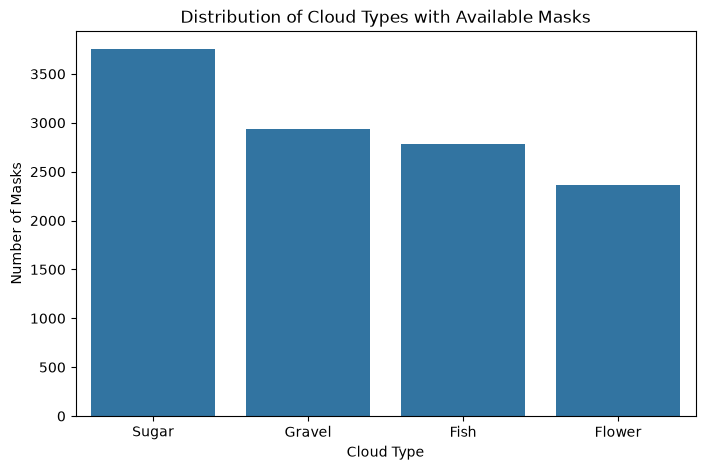

In [9]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=masked_df,
    x="Cloud_Type",
    order=masked_df["Cloud_Type"].value_counts().index
)

plt.title("Distribution of Cloud Types with Available Masks")
plt.xlabel("Cloud Type")
plt.ylabel("Number of Masks")

plt.show()

The visualization confirms that cloud categories are not equally represented in the dataset:

- Sugar has the highest number of available masks.
- Flower has the lowest number of available masks.

This plot provides a clearer view of the actual cloud presence compared to the initial annotation distribution.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.7 : Number of Unique Images

After analyzing the annotation records, the next step was to determine the number of unique satellite images in the training dataset.

Since each image is associated with four annotation records (one for each cloud category), the number of rows is greater than the number of unique images.

Calculating the number of unique images provides a better understanding of the actual size of the training dataset.

In [10]:
df["Image"].nunique()

5546

After analyzing annotation records, the actual number of satellite images in the training dataset was calculated.

The dataset contains **5,546 unique images**.

Since each image has four annotation records corresponding to the four cloud categories (Fish, Flower, Gravel, and Sugar), the total number of records is:

5,546 images × 4 cloud categories = 22,184 annotation records.

This confirms the structure of the dataset and shows that each image is associated with four cloud type annotations.

#### Step 1.7.1 : Check Mask Availability per Image
The purpose of this step is to verify that every image in the training dataset has at least one valid segmentation mask before performing further mask analysis.

In [11]:
mask_per_image = df.groupby("Image")["EncodedPixels"].count()

mask_per_image.head()

Image
0011165.jpg    2
002be4f.jpg    3
0031ae9.jpg    3
0035239.jpg    2
003994e.jpg    3
Name: EncodedPixels, dtype: int64

In [12]:
(mask_per_image == 0).sum()

np.int64(0)

The availability of segmentation masks was checked for each image.

Since each image contains four cloud category annotations, the number of available masks per image was counted.

The analysis shows that **all images contain at least one available segmentation mask**.

No image was found without any cloud annotation, which confirms that all training images contain at least one labeled cloud region.

### Step 1.7.2 : Number of Masks per Image Distribution

To better understand the complexity of each satellite image, the number of available segmentation masks per image was analyzed.

In [13]:
mask_per_image.value_counts().sort_index()

EncodedPixels
1    1348
2    2372
3    1560
4     266
Name: count, dtype: int64

* 1 mask  → 1348 images
* 2 masks → 2372 images
* 3 masks → 1560 images
* 4 masks → 266 images

/tmp/ipykernel_3789/617003069.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


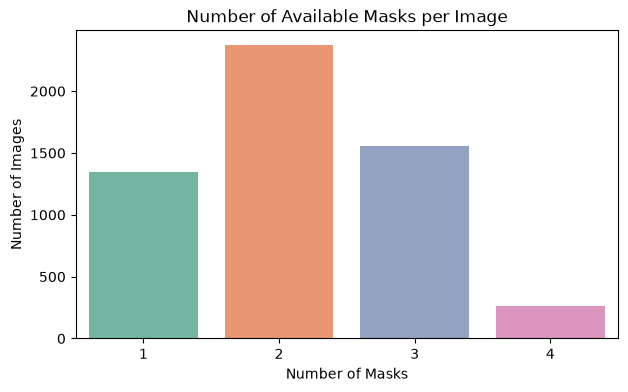

In [14]:
plt.figure(figsize=(7,4))

sns.countplot(
    x=mask_per_image,
    palette="Set2"
)

plt.title("Number of Available Masks per Image")
plt.xlabel("Number of Masks")
plt.ylabel("Number of Images")

plt.show()

The results show that images contain between 1 and 4 cloud categories:

- Most images contain 2 cloud masks.
- A significant number of images contain 3 cloud masks.
- Only a small number of images contain all four cloud categories.
- Some images contain only one cloud category.

This analysis shows that most satellite images contain multiple cloud types, which reflects the complexity of the segmentation task.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.8 : RLE Feature Extraction and Mask Characteristics

# 👩‍💻
df["EncodedPixels"] -> 20056 257 20440 257 20824 257 for example
1. What type of data? ->string==> int-> map(function, iterable)-->map(int, rle.split())--->list-->[20056,257,20440,257]
2. Does this text have any information inside it? ->start position (even)+ length (odd)->20056 257--> starts = numbers[0::2]=20056,20440,20824// lengths = numbers[1::2]->257,257,257

```python
numbers = list(map(int, rle.split()))
starts = numbers[0::2]
lengths = numbers[1::2]
```

3. What is important to me for cloud analytics?->Extracting useful cloud features:
* How big? total cloud pixels->257 + 257 + 257 = 771 pixels->
```python
total_pixels = sum(lengths)
```
- an estimation of the cloud area inside the image
* How many regions does this cloud have?Each start-length pair represents one separated cloud region:
- 20056 257
- 20440 257
- 20824 257-->3-> 
```python
num_runs = len(lengths)
```
- This indicates how fragmented or continuous the cloud mask is.
4. the typical size of cloud regions.?->Average cloud region size?
```python
mean_length = np.mean(lengths)
```
5. the biggest cloud area?--> Maximum cloud region size
```python
max_length = np.max(lengths)
```
6. The smallest continuous cloud segment?->Minimum cloud region size
```python
min_length = np.min(lengths)
```


### RLE Feature Extraction Workflow

**EncodedPixels**  
↓  
**String representation**  
↓  
**Convert string values into numbers**  
↓  
**Separate start positions and lengths**  
↓  
**Analyze length values**  
↓  
**Create numerical features**

In [15]:
def extract_rle_features(rle):
    if pd.isna(rle):
        return pd.Series({
            "num_runs":0,
            "mean_length":0,
            "max_length":0,
            "min_length":0,
            "total_pixels":0
        })

    numbers = list(map(int, rle.split()))

    starts = numbers[0::2]
    lengths = numbers[1::2]

    return pd.Series({
        "num_runs":len(lengths),
        "mean_length":np.mean(lengths),
        "max_length":np.max(lengths),
        "min_length":np.min(lengths),
        "total_pixels":np.sum(lengths)
    })

features = df["EncodedPixels"].apply(extract_rle_features)

df = pd.concat([df, features], axis=1)
df.head()

,Image_Label,EncodedPixels,Image,Cloud_Type,num_runs,mean_length,max_length,min_length,total_pixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,Fish,273.0,257.000000,257.0,257.0,70161.0
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,Flower,310.0,280.664516,289.0,1.0,87006.0
2,0011165.jpg_Gravel,NaN,0011165.jpg,Gravel,0.0,0.000000,0.0,0.0,0.0
3,0011165.jpg_Sugar,NaN,0011165.jpg,Sugar,0.0,0.000000,0.0,0.0,0.0
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,Fish,541.0,234.288355,242.0,1.0,126750.0


The `EncodedPixels` column stores segmentation masks using Run-Length Encoding (RLE). Since this format is stored as a string, it cannot be directly analyzed.

To extract useful information, the RLE values were converted into numerical values and separated into start positions and segment lengths.

From these values, several mask-related features were created:

- **num_runs**: number of separate cloud regions in the mask.
- **total_pixels**: total number of pixels belonging to the cloud region.
- **mean_length**: average size of cloud segments.
- **max_length**: largest continuous cloud segment.
- **min_length**: smallest continuous cloud segment.

These extracted features provide quantitative information about cloud size, structure.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## Step 1.9 : Exploratory Analysis of RLE Features

After extracting RLE-based features, an exploratory analysis was performed to better understand the characteristics of cloud masks.

### Main Questions

- What are the general characteristics of annotation records after feature extraction?
- How are cloud mask sizes distributed?
- Are clouds typically small or large?
- Are there differences between cloud types?
- Are there any outliers in the extracted features?

In [16]:
df[
    [
        "num_runs",
        "total_pixels",
        "mean_length",
        "max_length",
        "min_length"
    ]
].describe()

,num_runs,total_pixels,mean_length,max_length,min_length
count,22184.000000,22184.000000,22184.000000,22184.000000,22184.000000
mean,202.349125,33288.303237,95.974301,367.946448,39.010142
std,234.177823,42695.032050,1079.570414,5053.836186,1059.980216
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000
50%,142.000000,15717.000000,80.000000,92.000000,1.000000
75%,360.000000,56787.000000,155.000000,197.000000,1.000000
max,1242.000000,217369.000000,157440.000000,190075.000000,157440.000000


### Step 1.9.1 : Statistical Summary of Extracted RLE Features

A statistical summary was generated to obtain an initial overview of the extracted RLE features.

Since the dataset contains annotations without available masks, some feature values are equal to zero. Therefore, this summary provides an overview of the complete annotation dataset, while further mask-specific analysis will be performed only on available segmentation masks.

- **count = 22,184**  
  Represents the total number of annotation records analyzed.

- **num_runs**  
  Mean = 202, Maximum = 1242.  
  This indicates that some masks contain highly fragmented or complex cloud regions.

- **total_pixels**  
  Mean = 33,288 pixels, Maximum = 217,369 pixels.  
  Cloud areas show large variation between different masks.

- **mean_length**  
  Mean = 95.97, Standard deviation = 1079.57, Maximum = 157,440.  
  The large difference between the mean and standard deviation suggests the presence of extreme values (outliers) affecting the distribution.

- **max_length**  
  Mean = 367, Maximum = 190,075.  
  Some cloud segments contain very large continuous regions.

- **min_length**  
  Median = 1 pixel.  
  This indicates that some masks contain very small cloud segments.

A statistical summary was performed on the extracted RLE features to understand the characteristics of cloud masks.

The dataset contains **22,184 annotation records**, including records without masks where the extracted features are equal to zero.

The analysis shows that cloud masks have different levels of complexity:

- The average number of cloud regions (`num_runs`) is around 202, with a maximum of 1242 regions.
- The average cloud area (`total_pixels`) is approximately 33,288 pixels, with large variations between masks.
- Some features such as `mean_length` and `max_length` show high variability, suggesting the presence of large outliers.

Further visualization will be used to better understand feature distributions and detect possible anomalies.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.9.2 : Distribution of Cloud Area (total_pixels)

Analysis of cloud size distribution using total_pixels

#### Questions to Explore

Before visualizing the cloud area distribution, we aim to answer the following questions:

- How are cloud mask sizes distributed in the dataset?
- Are most cloud regions small, medium, or large?
- Are there any extreme values or outliers in cloud areas?

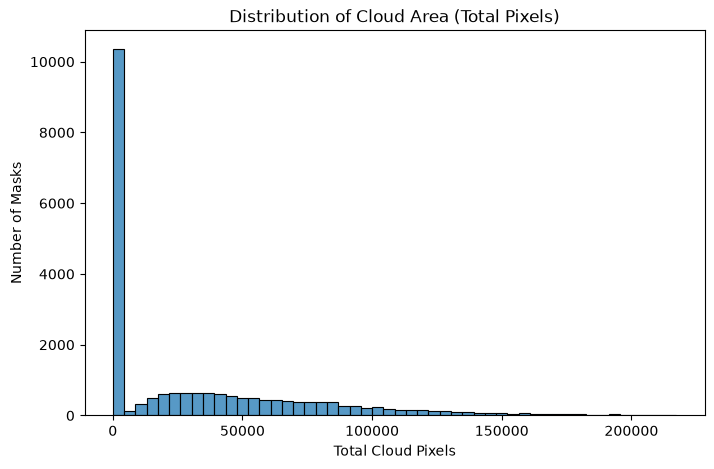

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="total_pixels",
    bins=50
)

plt.title("Distribution of Cloud Area (Total Pixels)")
plt.xlabel("Total Cloud Pixels")
plt.ylabel("Number of Masks")

plt.show()

### Note on Mask Availability

For RLE feature visualization, only images with available segmentation masks were considered.

Records without masks were excluded because their extracted features were set to zero during preprocessing, which could dominate the distribution and hide the real variation of cloud areas.

In [18]:
features = masked_df["EncodedPixels"].apply(extract_rle_features)

masked_df = pd.concat([masked_df, features], axis=1)
masked_df.head()

,Image_Label,EncodedPixels,Image,Cloud_Type,num_runs,mean_length,max_length,min_length,total_pixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,Fish,273.0,257.000000,257.0,257.0,70161.0
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,Flower,310.0,280.664516,289.0,1.0,87006.0
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,Fish,541.0,234.288355,242.0,1.0,126750.0
5,002be4f.jpg_Flower,100850 142 101234 142 101618 142 102002 142 10...,002be4f.jpg,Flower,313.0,142.000000,142.0,142.0,44446.0
7,002be4f.jpg_Sugar,5074 96 5458 96 5842 96 6226 96 6610 96 6994 9...,002be4f.jpg,Sugar,246.0,96.000000,96.0,96.0,23616.0


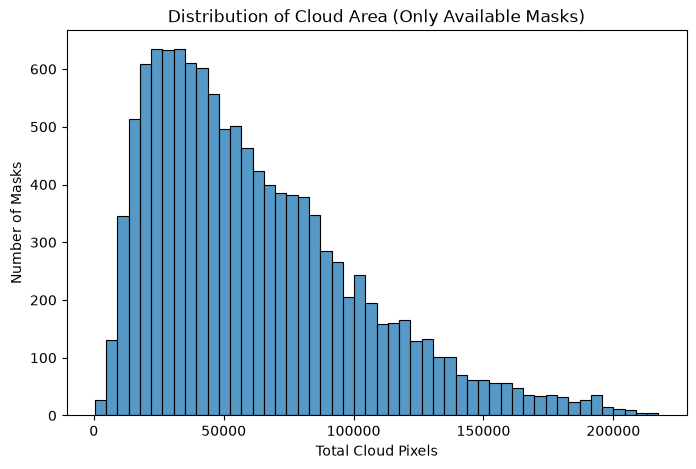

In [19]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=masked_df,
    x="total_pixels",
    bins=50
)

plt.title("Distribution of Cloud Area (Only Available Masks)")
plt.xlabel("Total Cloud Pixels")
plt.ylabel("Number of Masks")

plt.show()

### Observation

The histogram shows that the cloud area distribution is concentrated near the lower values of the x-axis, with a long tail extending toward higher values.

This indicates that:

- Most cloud masks have small to medium areas.
- Only a small number of cloud masks contain very large regions.
- The distribution is right-skewed, meaning that a few large cloud masks strongly affect the overall variability.
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.9.3 : Outlier Detection

### Questions

- Are there any outliers in cloud area?
- How far are they from the majority of observations?
- Should they be removed or simply investigated?

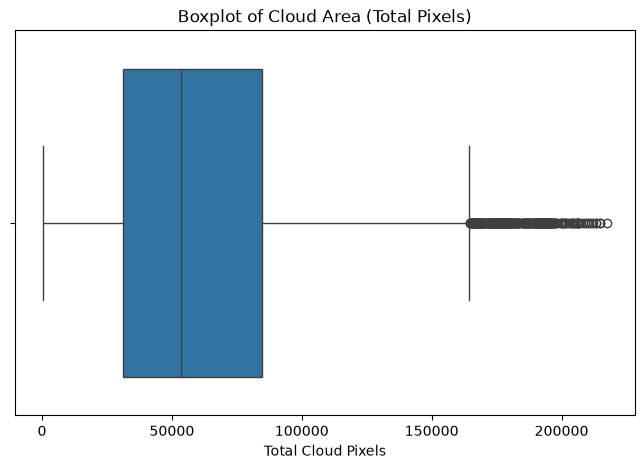

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=masked_df,
    x="total_pixels"
)

plt.title("Boxplot of Cloud Area (Total Pixels)")
plt.xlabel("Total Cloud Pixels")

plt.show()

### Boxplot Analysis of Cloud Area (`total_pixels`)

To better understand the distribution of cloud mask sizes and identify potential extreme values, a boxplot was created using the `total_pixels` feature.

The central line inside the box represents the median value, where 50% of observations are below this value and 50% are above it.

In this boxplot, the median is located closer to the lower quartile of the box, indicating that the distribution is not symmetric. The longer upper whisker and the extension toward higher values suggest a right-skewed distribution.

The upper whisker represents the range of typical cloud mask sizes, while observations beyond this range are considered potential outliers.

These outliers correspond to cloud masks with significantly larger areas compared to the majority of observations. They may represent very large cloud regions and should be investigated further rather than automatically removed.

### Answers to Exploration Questions

**1) How are cloud mask sizes distributed?**  
→ Cloud mask sizes are not evenly distributed and show a right-skewed distribution.

**2) Are clouds typically small or large?**  
→ Most cloud masks have relatively smaller areas, while a limited number of masks contain very large cloud regions.

**3) Are there any outliers?**  
→ Yes, several observations with unusually large `total_pixels` values are detected.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.9.4 : Quantifying Outliers Using IQR

In [21]:
Q1 = masked_df["total_pixels"].quantile(0.25)
Q3 = masked_df["total_pixels"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 31186.25
Q3: 84625.25
IQR: 53439.0
Lower Bound: -48972.25
Upper Bound: 164783.75


In [22]:
outliers = masked_df[
    masked_df["total_pixels"] > upper_bound
]

print("Number of outliers:", len(outliers))

Number of outliers: 271


In [23]:
outlier_percentage = len(outliers) / len(masked_df) * 100

print("Outlier percentage:", outlier_percentage)

Outlier percentage: 2.289624873267996



To quantify the extreme values observed in the boxplot, the Interquartile Range (IQR) method was applied to the `total_pixels` feature.

The IQR method defines the normal range of observations based on the first quartile (Q1) and the third quartile (Q3). Values above the upper bound are considered potential outliers.

The calculated values are:

- **Q1:** 31,186.25 pixels
- **Q3:** 84,625.25 pixels
- **IQR:** 53,439 pixels
- **Lower Bound:** -48,972.25 pixels
- **Upper Bound:** 164,783.75 pixels

Based on this criterion, **271 cloud masks** were identified as potential outliers.

Considering the total number of available masks, these observations represent a small proportion of the dataset. These values correspond to cloud regions with significantly larger areas compared to the majority of masks.

I think these outliers should not be automatically removed, as they may represent valid large cloud formations rather than annotation errors.

### Decision on Outliers

The detected outliers were not removed at this stage.

Since this dataset represents real satellite cloud segmentation, large cloud regions may correspond to valid observations rather than errors.

Removing these samples could result in losing important information about large cloud formations.

Therefore, these observations will be kept.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.10 : Cloud Type Comparison

### Questions to Explore

- Do different cloud types have different mask sizes?
- Which cloud type tends to occupy larger image areas?
- Are some cloud types more fragmented than others?

#### Step 1.10.1 : Compare Cloud Area Between Cloud Types

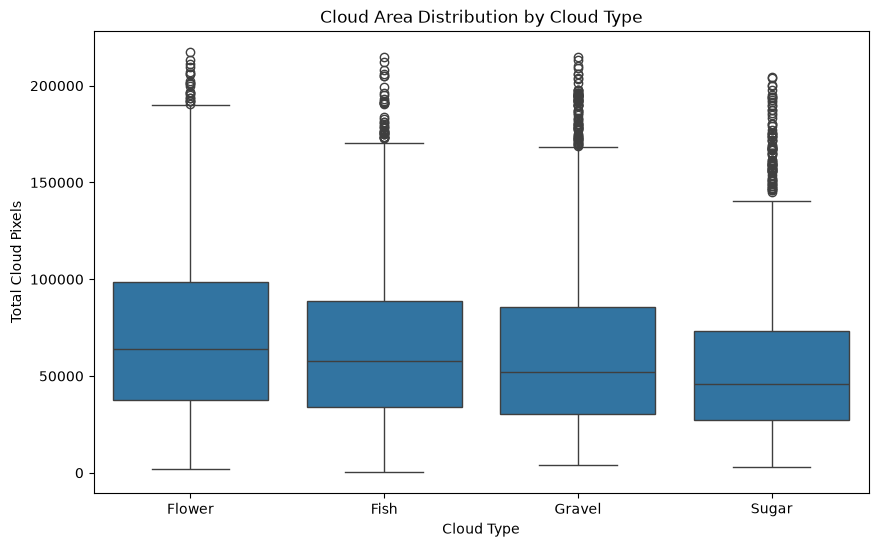

In [24]:
order = (
    masked_df["Cloud_Type"]
    .value_counts()
    .sort_values()
    .index
)

#order
#How large is the cloud?Cloud size-->total_pixels

plt.figure(figsize=(10,6))

sns.boxplot(
    data=masked_df,
    x="Cloud_Type",
    y="total_pixels",
    order=order
)

plt.title("Cloud Area Distribution by Cloud Type")
plt.xlabel("Cloud Type")
plt.ylabel("Total Cloud Pixels")

plt.show()


### Cloud Area Distribution by Cloud Type

To investigate whether cloud types have different spatial characteristics, the distribution of `total_pixels` was compared across the four cloud categories using a boxplot.

The boxplot shows that cloud area distributions are not identical across cloud types. All categories exhibit right-skewed distributions, with longer upper whiskers and observations beyond the whiskers. This indicates that most cloud masks have relatively smaller areas, while a limited number of masks contain much larger cloud regions.

By comparing the median values, Flower clouds appear to have a higher median `total_pixels` value compared to the other categories, suggesting that they tend to occupy larger areas on average.

The interquartile range (IQR) was also compared between cloud types. Flower clouds show a wider box, indicating greater variability in cloud area sizes within this category. In addition, the longer upper whisker suggests that Flower clouds can contain larger cloud regions compared to the other categories.

Regarding outliers, extreme values are observed across all cloud types rather than being concentrated in a single category. This indicates that very large cloud formations can occur in different cloud categories.

Overall, the analysis suggests that cloud types may have different spatial characteristics. Flower clouds appear to have larger and more variable cloud areas, while other categories also contain large cloud regions. 

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

#### Step 1.10.2 : Cloud Mask Complexity by Cloud Type

#### Motivation for Analyzing Mask Complexity (`num_runs`)

The previous analysis focused on the cloud area using the `total_pixels` feature, which measures the number of pixels belonging to a cloud mask.

However, cloud area alone does not fully describe the characteristics of a cloud mask. Two cloud regions can have a similar number of pixels while having completely different shapes and structures.

For example, one cloud mask can be a large continuous region, while another cloud mask can be fragmented into multiple separated regions. Although their total number of cloud pixels may be similar, their spatial complexity is different.

Therefore, an additional feature is required to describe the shape complexity of segmentation masks.

The `num_runs` feature extracted from the RLE representation is used for this purpose. It represents the number of consecutive pixel segments required to describe the mask.

A higher number of runs indicates a more fragmented and complex cloud structure, while a lower number of runs suggests a simpler and more continuous cloud region.

Therefore, comparing `num_runs` across cloud types helps us investigate whether different cloud categories have different structural characteristics beyond their size.

#### Questions to Explore

- Do different cloud types have different mask complexities?
- Which cloud type tends to have more fragmented masks?
- Are some cloud types more complex in shape than others?

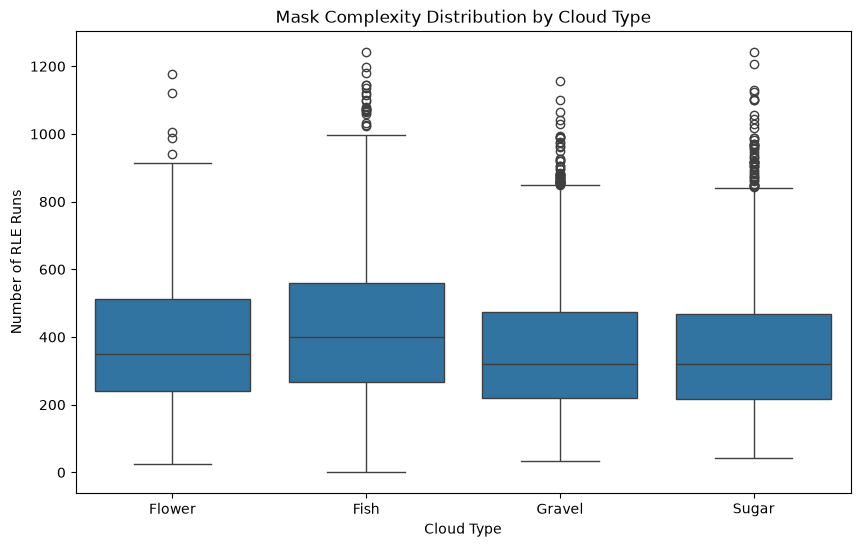

In [25]:
plt.figure(figsize=(10,6))

#How complicated is the cloud shape?Cloud complexity-->num_runs

sns.boxplot(
    data=masked_df,
    x="Cloud_Type",
    y="num_runs",
    order=order
)

plt.title("Mask Complexity Distribution by Cloud Type")
plt.xlabel("Cloud Type")
plt.ylabel("Number of RLE Runs")

plt.show()

After analyzing cloud area using `total_pixels`, the complexity of cloud masks was investigated using the `num_runs` feature.

The `num_runs` feature represents the number of consecutive pixel segments required to describe a cloud mask. A higher number of runs indicates a more fragmented and complex cloud structure.

The boxplot comparison shows differences in mask complexity between cloud types.

Fish clouds appear to have a higher median `num_runs` value compared to the other categories, suggesting that they tend to have more complex mask structures. In addition, Fish shows a wider interquartile range (IQR), indicating greater variability in mask complexity within this category.

The whisker range also suggests that some cloud types can contain masks with highly complex structures. Outliers are observed across different cloud categories, indicating that highly fragmented cloud regions are not limited to a single cloud type.

Overall, the results suggest that cloud types may differ not only in their area coverage but also in their structural complexity. Fish clouds appear to show higher complexity and variability, while other categories also contain complex cloud masks.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.10.3 : Correlation Analysis of RLE Features

After analyzing cloud area (`total_pixels`) and mask complexity (`num_runs`) separately, the relationship between extracted RLE features is investigated.

Understanding the correlation between these features helps determine whether they provide complementary information or describe similar aspects of cloud masks.

#### Questions to Explore

- Is there a relationship between cloud size and mask complexity?
- Do larger cloud regions tend to have more fragmented structures?
- Are some extracted features strongly correlated with each other?

In [26]:
masked_df[
    [
        "num_runs",
        "total_pixels",
        "mean_length",
        "max_length",
        "min_length"
    ]
].corr()

,num_runs,total_pixels,mean_length,max_length,min_length
num_runs,1.000000,0.766727,-0.020956,-0.034202,-0.044227
total_pixels,0.766727,1.000000,0.056468,0.167274,0.011519
mean_length,-0.020956,0.056468,1.000000,0.245734,0.988018
max_length,-0.034202,0.167274,0.245734,1.000000,0.210001
min_length,-0.044227,0.011519,0.988018,0.210001,1.000000


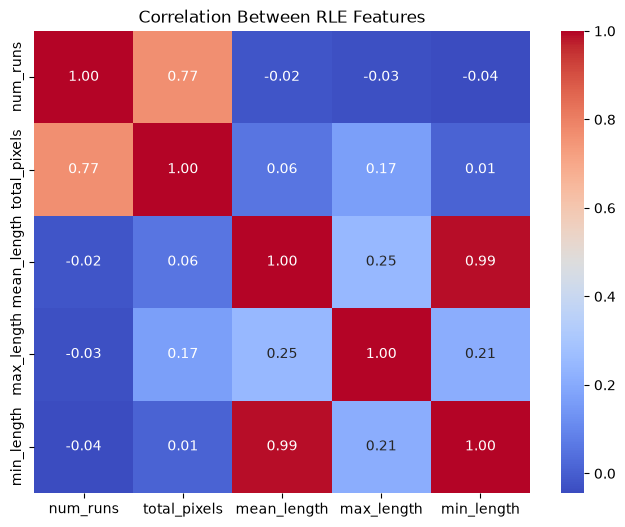

In [27]:
corr_features = masked_df[
    [
        "num_runs",
        "total_pixels",
        "mean_length",
        "max_length",
        "min_length"
    ]
].corr()


plt.figure(figsize=(8,6))

sns.heatmap(
    corr_features,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between RLE Features")

plt.show()

#### Correlation Analysis of RLE Features

A correlation heatmap was generated to explore the relationships between the extracted RLE features.

The strongest relationship is observed between `num_runs` and `total_pixels` (correlation = 0.77). This suggests that larger cloud masks generally contain more RLE segments, indicating that cloud size and mask complexity are positively related.

A very strong positive correlation is found between `mean_length` and `min_length` (correlation = 0.99 ≈ 1), suggesting that these two features carry very similar information and may be considered during feature selection in the modeling stage --> High correlation between features, meaning they contain similar information--> multicollinearity.

The remaining feature pairs show weak or negligible correlations.
Similarly, `num_runs` has almost no correlation with `mean_length`, `max_length`, or `min_length`, indicating that the number of cloud segments provides information that is largely independent of individual segment lengths.

Overall, the correlation analysis shows that the extracted RLE features capture different aspects of cloud masks. While cloud size and mask complexity are moderately related, most segment-length features provide complementary information rather than redundant measurements.

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.11 : Visual Validation of Cloud Masks

Numerical features alone cannot confirm whether the reconstructed masks correctly represent the actual cloud regions in the original satellite images.

Although features such as `total_pixels` and `num_runs` provide information about cloud size and structural complexity, they do not show the spatial distribution and shape of the cloud regions.

Therefore, the RLE encoding is decoded to reconstruct the binary cloud masks for visual inspection.

📎 The RLE encoding is converted into a binary mask, where:

- `1` represents cloud pixels.
- `0` represents background pixels.

Example:

```text
EncodedPixels (RLE)

20056 257 20440 257 20824 257 ...

        ↓ RLE Decoding

Binary Mask (for example)

0 0 1 0
0 1 1 1
1 0 1 0
```

The reconstructed masks are then compared with the original satellite images to validate the segmentation information and better understand the spatial characteristics of different cloud structures.

#### Questions

- Can the RLE encoding be correctly reconstructed into a binary mask?
- Does the reconstructed mask accurately correspond to the cloud regions in the satellite images?
- Do the visual characteristics of the cloud masks agree with the numerical features extracted from the RLE encoding?

In [28]:
masked_df.iloc[0]["Image"]

'0011165.jpg'

In [29]:
from PIL import Image

img = Image.open("/home/ubuntu/Cloud_Project/train_images/0011165.jpg")

img.size

(576, 384)

#### Image Dimension Verification

Before reconstructing the cloud masks, the original satellite image dimensions are verified because the binary mask must have the same spatial dimensions as the input image.

The **Pillow** library is used to read the image files and extract their dimensions.

Example:

```python
from PIL import Image

img = Image.open("path_to_image/image.jpg")

img.size

```

--> The returned size corresponds to:

* Width: ```576 ``` pixels
* Height: ```384``` pixels

The mask is then reconstructed using the same dimensions as the original image to ensure that each mask pixel corresponds to the correct image pixel.

In [30]:
def rle_decode(rle, shape=(384, 576)):
    
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    if pd.isna(rle):
        return mask.reshape(shape)

    numbers = list(map(int, rle.split()))

    starts = numbers[0::2]
    lengths = numbers[1::2]

    for start, length in zip(starts, lengths):
        start -= 1
        mask[start:start+length] = 1

    return mask.reshape(shape)

In [31]:
#Decode

# uint8 is used because the mask contains only small integer values (0 = background, 1 = cloud)
# mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
# Create an empty 1D binary mask with the same number of pixels as the image.
# Pixels are initialized as 0 (background); cloud pixels will later be set to 1.

#def rle_decode(rle, shape=(384, 576)):
    
    #mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    #if pd.isna(rle):
        #return mask.reshape(shape)
# If no RLE annotation exists, return an empty mask (all background pixels)
    #numbers = list(map(int, rle.split()))
    # Split the RLE string and convert the values from strings to integers

    #starts = numbers[0::2]
    #lengths = numbers[1::2]

    #for start, length in zip(starts, lengths):
        # Fill cloud pixels in the mask using RLE start positions and lengths.
        #start -= 1. # Convert RLE 1-based indexing to Python 0-based indexing: 1 → 0
        #mask[start:start+length] = 1 
        # Mark cloud pixels as 1--> 
        #EXP) start = 10 length = 5==>mask[10:15] = 1--> 0 0 0 0 0 0 0 0 0 0 0 0 0==> 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1

    #return mask.reshape(shape) # # Convert the 1D mask array into the original image dimensions: 221184 values--->384 × 576 matrix

### Step 1.11.2 : RLE Decoding Validation

In [32]:
display(masked_df.head())

# Select one sample with an available cloud mask
sample = masked_df.iloc[0]

sample

,Image_Label,EncodedPixels,Image,Cloud_Type,num_runs,mean_length,max_length,min_length,total_pixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,Fish,273.0,257.000000,257.0,257.0,70161.0
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,Flower,310.0,280.664516,289.0,1.0,87006.0
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,Fish,541.0,234.288355,242.0,1.0,126750.0
5,002be4f.jpg_Flower,100850 142 101234 142 101618 142 102002 142 10...,002be4f.jpg,Flower,313.0,142.000000,142.0,142.0,44446.0
7,002be4f.jpg_Sugar,5074 96 5458 96 5842 96 6226 96 6610 96 6994 9...,002be4f.jpg,Sugar,246.0,96.000000,96.0,96.0,23616.0


Image_Label                                       0011165.jpg_Fish
EncodedPixels    20056 257 20440 257 20824 257 21208 257 21592 ...
Image                                                  0011165.jpg
Cloud_Type                                                    Fish
num_runs                                                     273.0
mean_length                                                  257.0
max_length                                                   257.0
min_length                                                   257.0
total_pixels                                               70161.0
Name: 0, dtype: object

In [33]:
mask = rle_decode(sample["EncodedPixels"])

mask.shape

(384, 576)

The decoded mask has the same spatial dimensions as the original satellite image

#### Validate the number of cloud 

The number of pixels marked as cloud in the decoded mask

should match the total_pixels extracted from the RLE encoding

This validates that the decoding process reconstructs the mask correctly

In [34]:
# Count cloud pixels from the decoded binary mask
decoded_pixels = mask.sum() #---> The pixels belonging to the cloud

# Compare with the total_pixels extracted from RLE features
print("Decoded cloud pixels:", decoded_pixels)
print("RLE total_pixels:", sample["total_pixels"])

# Check if both values are equal
print("Validation result:", decoded_pixels == sample["total_pixels"])

Decoded cloud pixels: 70161
RLE total_pixels: 70161.0
Validation result: True


☑️ Valid

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1.11.3 : Visualizing the Decoded Cloud Mask

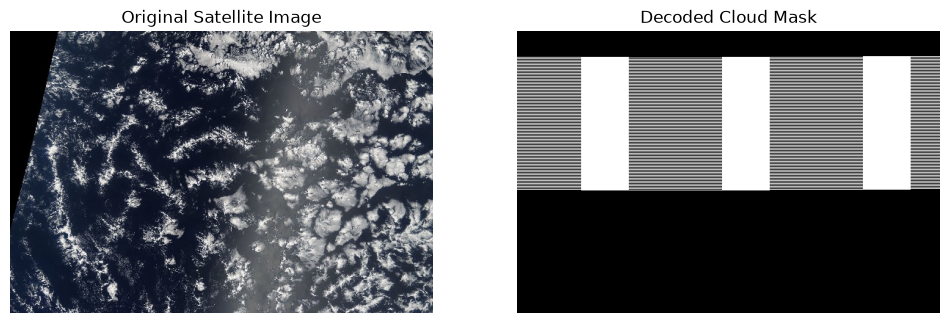

In [35]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original Satellite Image")
plt.axis("off")


plt.subplot(1,2,2)
plt.imshow(mask, cmap="gray")
plt.title("Decoded Cloud Mask")
plt.axis("off")

plt.show()

### Step 1.11.4 : Overlay Mask on Original Satellite Image

The decoded cloud mask is overlaid on the original satellite image to visually validate whether the reconstructed mask correctly represents the actual cloud region.

#### Question

- Does the reconstructed mask accurately correspond to the cloud region in the satellite image?

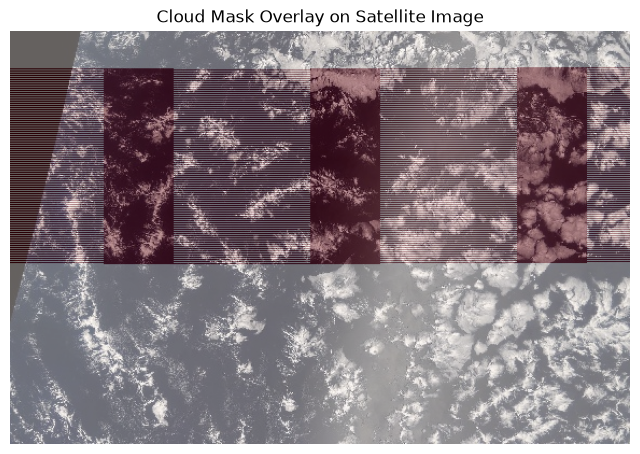

In [40]:
plt.figure(figsize=(8,6))

plt.imshow(img)

plt.imshow(mask, cmap="Reds", alpha=0.4)

plt.title("Cloud Mask Overlay on Satellite Image")
plt.axis("off")

plt.show()

The decoded mask was overlaid on the original satellite image to visually verify whether the reconstructed cloud regions correspond to the actual cloud structures.

The overlay visualization shows that the reconstructed mask identifies several cloud regions within the satellite image. 

-------------------------------------------------------------------------------------------------------------------------------------------------

### Step 1 Summary

Through this exploratory analysis, the dataset structure, cloud annotations, mask characteristics, and spatial properties of cloud regions were investigated.

The RLE annotations were successfully decoded into binary masks, and numerical as well as visual validations confirmed that the reconstructed masks correctly represent the cloud regions.

The analysis revealed differences between cloud categories in terms of:
- cloud area (`total_pixels`)
- mask complexity (`num_runs`)
- spatial structure

These findings provide a better understanding of the dataset before moving to the next stages of cloud segmentation modeling.